# Инклюды и подготовка

In [91]:
import pandas as pd
import requests
import time
# import urllib.parse
# import unidecode
# import unicodedata
import os
import re

# from typing import Any, Dict, Optional
import ast

from collections import Counter

import numpy  as np

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split  
from sklearn.ensemble import RandomForestRegressor 
from sklearn import metrics
from sklearn.inspection import permutation_importance


# from scipy import sparse
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm
from lightgbm import LGBMRegressor


nltk.download('vader_lexicon')


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/administrator/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [6]:
print(f"pandas     : {pd.__version__}")
print(f"numpy      : {np.__version__}")
print(f"nltk       : {nltk.__version__}")
print(f"sklearn    : {sklearn.__version__}")
print(f"matplotlib : {matplotlib.__version__}")
print(f"seaborn    : {sns.__version__}")
print(f"lightgbm   : {lightgbm.__version__}")

pandas     : 2.3.3
numpy      : 2.2.6
nltk       : 3.10.4
sklearn    : 1.7.2
matplotlib : 3.10.0
seaborn    : 0.13.2
lightgbm   : 4.7.0


In [7]:
# Используем фиксированное значение для генератора случайных чисел, чтобы результаты были воспроизводимыми
# 42 - просто устоявшееся конвенционное значение
RANDOM_STATE = 42

In [8]:
train_dataset_df = pd.read_csv('data/competition/hotels_train.zip')
test_dataset_df = pd.read_csv('data/competition/hotels_test.zip')
train_dataset_df['test_dataframe'] = 0
test_dataset_df['test_dataframe'] = 1

In [9]:
hotels =  pd.concat([train_dataset_df, test_dataset_df], ignore_index=True)
hotels.head(3)

,hotel_address,additional_number_of_scoring,review_date,average_score,hotel_name,reviewer_nationality,negative_review,review_total_negative_word_counts,total_number_of_reviews,positive_review,review_total_positive_word_counts,total_number_of_reviews_reviewer_has_given,reviewer_score,tags,days_since_review,lat,lng,test_dataframe
0,Stratton Street Mayfair Westminster Borough Lo...,581,2/19/2016,8.4,The May Fair Hotel,United Kingdom,Leaving,3,1994,Staff were amazing,4,7,10.0,"[' Leisure trip ', ' Couple ', ' Studio Suite ...",531 day,51.507894,-0.143671,0
1,130 134 Southampton Row Camden London WC1B 5AF...,299,1/12/2017,8.3,Mercure London Bloomsbury Hotel,United Kingdom,poor breakfast,3,1361,location,2,14,6.3,"[' Business trip ', ' Couple ', ' Standard Dou...",203 day,51.521009,-0.123097,0
2,151 bis Rue de Rennes 6th arr 75006 Paris France,32,10/18/2016,8.9,Legend Saint Germain by Elegancia,China,No kettle in room,6,406,No Positive,0,14,7.5,"[' Leisure trip ', ' Solo traveler ', ' Modern...",289 day,48.845377,2.325643,0


# Очистка и наполнение

По поводу категориальных признаков.

Так как я  буду использовать не линейный градиент, а градиентный бустинг на основе LightGBM, то нет смысла танцевать вокруг one-hot в категориальных признаках (типа частей дат), везде, где применимо, буду использовать cat.code



### Заполняем лат/лон

Пропуски у нас в лат/лон, по-этому видится простым и логичным решением запросить координаты по адресу из датасета с публичного апи, например Openstreetmaps/Photon/Yandex Geocoder и т.д. 

В датасете частично  убиты адреса, в которых содержались символы национальных алфавитов, сравним например адрес отеля "Austria Trend Hotel Schloss Wilhelminenberg Wien" из датасета с его реальным  адресом

датасет: Savoyenstra e 2 16 Ottakring 1160 Vienna Austria

реальность: Savoyenstraße 2, 1160 Wien, Österreich

или "Rue Damrémont, 18e arrondissement, 75018 Paris, France" в датасете выглядит как "Rue Damr mont 18th arr 75018 Paris France"

In [10]:
display(hotels.iloc[122])
display(hotels.iloc[566])


hotel_address                                  Savoyenstra e 2 16 Ottakring 1160 Vienna Austria
additional_number_of_scoring                                                                 86
review_date                                                                           8/26/2016
average_score                                                                               8.3
hotel_name                                     Austria Trend Hotel Schloss Wilhelminenberg Wien
reviewer_nationality                                                  United States of America 
negative_review                                                                        Not much
review_total_negative_word_counts                                                             3
total_number_of_reviews                                                                    1558
positive_review                                                       Bugs in our room Bad Wifi
review_total_positive_word_counts       

hotel_address                                      23 Rue Damr mont 18th arr 75018 Paris France
additional_number_of_scoring                                                                 21
review_date                                                                           6/23/2016
average_score                                                                               8.3
hotel_name                                                         Holiday Inn Paris Montmartre
reviewer_nationality                                                            United Kingdom 
negative_review                                                                             N a
review_total_negative_word_counts                                                             3
total_number_of_reviews                                                                     298
positive_review                                  Great location friendly and very helpful staff
review_total_positive_word_counts       

In [11]:

def normalize_address(df: pd.DataFrame):
    """
    Попытка превратить убитые неправильными конвертациями кодировок адреса во что-то  удобоваримое
    """
    work_df: pd.DataFrame = df.copy()
    # print(work_df['hotel_address'].iloc[1])

    work_df['hotel_address'] = work_df['hotel_address'].str.replace(
        r'\s+', ' ', regex=True)

    # Не удалось уйти от захардкоженных замен, но такова жизнь
    replacements = {
        r'\barr\b': 'Arr',
        r'\bave\b': 'Avenue',
        r'\bstr\b': 'Street',
        r'\brd\b': 'Road',
        r'\bst\b': 'Saint',
        r'tra\se\b': 'trasse',
    }

    # Применяем все замены
    for pattern, replacement in replacements.items(): 
        work_df['hotel_address'] = work_df['hotel_address'].str.replace( pattern, replacement, regex=True )
        
    # Удаляем пробел между буквами, если там нет цифр
    # Это удалит пробел в "stra e",  но не тронет "Molenwerf 1".
    work_df['hotel_address'] = work_df['hotel_address'].str.replace(
        r'(?<=[a-zA-Z])\s(?=[a-zA-Z])', '', regex=True)

    # Разбиваем СловаЗаписанныеВОТТак на Слова Записанные ВОТ Так
    # print(work_df['hotel_address'].iloc[1])
    work_df['hotel_address'] = work_df['hotel_address'].str.replace(
        r'(?<=[a-z])(?=[A-Z])', ' ', regex=True)
    work_df['hotel_address'] = work_df['hotel_address'].str.replace(
        r'(?<=[A-Z])(?=[A-Z][a-z])', ' ', regex=True)
    # print(work_df['hotel_address'].iloc[1])

    # work_df['hotel_address'] = work_df['hotel_address'].str.replace(r'\s+', ' ', regex=True).str.strip()

    # --- Проверка ---
    # print(work_df['hotel_address'].head(20))

    return work_df

При тестировании обнаружилось,  что фотон намного лучше ищет по нечётким адресам, по-этому в дальнейшем я использовал его. Номинатем остался в качестве наследия, остальные варианты не тестировал, так как фотона оказалось достаточно 

In [12]:
REQV_HEADERS = {"User-Agent": "HotelApp/1.0 (tcheredeev@gmail.com)"}

def geocode_nominatim(address: str, countrycodes: str | None = None) -> dict | None:
    """
    Nominatim
    """
    params = {"q": address, "format": "json",
              "limit": 1, "accept-language": "en"}
    if countrycodes:
        params["countrycodes"] = countrycodes
    try:
        r = requests.get(
            "https://nominatim.openstreetmap.org/search",
            params=params,
            headers=REQV_HEADERS,
            timeout=10,
        )
        if r.status_code != 200:
            return None
        data = r.json()
        if not data:
            return None
        # print(data)
        return {
            "lat": float(data[0]["lat"]),
            "lon": float(data[0]["lon"]),
            "matched_name": data[0]["display_name"],
            "source": "nominatim",
        }
    except Exception:
        return None


def geocode_photon(address: str) -> dict | None:
    """
    Photon
    """
    try:
        r = requests.get(
            "https://photon.komoot.io/api/",
            params={"q": address, "limit": 1},
            headers=REQV_HEADERS,
            timeout=10,
        )
        data = r.json()
        # print(data)
        features = data.get("features", [])
        if not features:
            return None
        feat = features[0]
        props = feat["properties"]
        coords = feat["geometry"]["coordinates"]  # [lon, lat]
        return {
            "lat": coords[1],
            "lon": coords[0],
            "matched_name": props.get("name") or props.get("street"),
            "source": "photon",
        }
    except Exception:
        return None

Так же я использую кэширование найденных геоданных, что бы в случае каких-то ошибок или прерванного запроса к гео апи не перезапрашивать все по новой.

In [ ]:
def load_geocoding_cache(cache_path: str = "geocoding_cache.csv") -> pd.DataFrame:
    """
    Загрузка геокэша 
    """
    if os.path.exists(cache_path):
        try:
            df = pd.read_csv(cache_path)
            print(f"[КЭШ] Загружено: {len(df)} записей.")
            return df
        except Exception as e:
            print(f"[КЭШ] Ошибка чтения ({e}). Создаем новый.")
            return pd.DataFrame(columns=['hotel_address', 'lat', 'lng'])
    else:
        print("[КЭШ] Файл не найден. Создаем новый.")
        return pd.DataFrame(columns=['hotel_address', 'lat', 'lng'])

def save_geocoding_cache(df: pd.DataFrame, cache_path: str = "geocoding_cache.csv"):
    """
    Сохранение геокэша 
    """
    try:
        df.to_csv(cache_path, index=False)
    except Exception as e:
        print(f"[КЭШ] ОШИБКА сохранения: {e}")



In [ ]:
def enrich_missing_coords(
    df: pd.DataFrame,
    addr_col: str = "hotel_address",
    lat_col: str = "lat",
    lng_col: str = "lng",
    rate_limit_sleep: float = 0.3,
    cache_path: str = "geocoding_cache.csv",
) -> pd.DataFrame:
    """
    Дозаполнение lat/lng по кэшу и API Photon.
    """
    cache_df = load_geocoding_cache(cache_path)
    # Дедуп кэша по оригинальному адресу
    cache_df = cache_df.drop_duplicates(subset=addr_col, keep="last")

    # Строки без координат
    mask_missing = df[lat_col].isna() | df[lng_col].isna()
    subset = df.loc[mask_missing]
    if subset.empty:
        print("[ГЕО] Все координаты уже заполнены.")
        return df.copy()

    # Уникаобные адреса
    unique_addrs = subset[[addr_col]].drop_duplicates().reset_index(drop=True)

    # Сопоставление с кэшем
    merged = unique_addrs.merge(
        cache_df[[addr_col, lat_col, lng_col]],
        on=addr_col,
        how="left",
        suffixes=("", "_cache"),
        indicator=True,
    )

    to_geocode = merged[merged["_merge"] == "left_only"].copy()

    print(f"[ГЕО] Строк без координат:      {len(subset)}")
    print(f"[ГЕО] Уникальных адресов:       {len(unique_addrs)}")
    print(f"[ГЕО] Найдено в кэше:           {len(merged) - len(to_geocode)}")
    print(f"[ГЕО] Новых для API:            {len(to_geocode)}")

    # Запрос по нормализованному адресу.
    # В кэш идёт оригинальный
    saved_count = 0
    for cnt, (_, row) in enumerate(to_geocode.iterrows(), start=1):
        original_addr = row[addr_col]

        try:
            addr_norm = normalize_address(pd.DataFrame([{addr_col: original_addr}]))[addr_col].iloc[0]


            res = geocode_photon(addr_norm)

            r = f"lat: {res['lat']}, lon: {res['lon']}" if res else "None"
            print(f"{cnt} of {len(to_geocode)}")
            print(f"original  : {original_addr}")
            print(f"normalized: {addr_norm}")
            print(f"result    : {r}\n")

            if res is not None:
                new_row = pd.DataFrame([{
                    addr_col: original_addr,
                    lat_col: res["lat"],
                    lng_col: res["lon"],
                }])
                if cache_df.empty:
                    cache_df = new_row.copy()
                else:
                    cache_df = pd.concat([cache_df, new_row], ignore_index=True)

                # Сохраняем кэш сразу после каждого нового адреса
                save_geocoding_cache(cache_df, cache_path)
                saved_count += 1

            time.sleep(rate_limit_sleep)

        except Exception as e:
            print(f"Ошибка поиска адреса '{original_addr}': {e}")
            time.sleep(rate_limit_sleep * 5)

    print(f"Записано в кэш: {saved_count}")

    # Записываем координаты
    result = df.copy()

    result = result.merge(
        cache_df[[addr_col, lat_col, lng_col]],
        on=addr_col,
        how="left",
        suffixes=("", "_cache"),
    )

    # Если в кэше нашлись координаты — заполняем пропуски
    if f"{lat_col}_cache" in result.columns:
        result[lat_col] = result[lat_col].fillna(result[f"{lat_col}_cache"])
        result[lng_col] = result[lng_col].fillna(result[f"{lng_col}_cache"])
        result = result.drop(columns=[f"{lat_col}_cache", f"{lng_col}_cache"])

    return result


In [15]:
GEOCODING_CACHE_FILE = "data/geocoding_cache.csv"
hotels = enrich_missing_coords(hotels, cache_path=GEOCODING_CACHE_FILE)

print(f"\nВсего координат в датафрейме: {hotels['lat'].notna().sum()}")

[КЭШ] Загружено: 17 записей.
[ГЕО] Строк без координат:      3268
[ГЕО] Уникальных адресов:       17
[ГЕО] Найдено в кэше:           17
[ГЕО] Новых для API:            0
Записано в кэш: 0

Всего координат в датафрейме: 515738


In [16]:
hotels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Data columns (total 18 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   hotel_address                               515738 non-null  object 
 1   additional_number_of_scoring                515738 non-null  int64  
 2   review_date                                 515738 non-null  object 
 3   average_score                               515738 non-null  float64
 4   hotel_name                                  515738 non-null  object 
 5   reviewer_nationality                        515738 non-null  object 
 6   negative_review                             515738 non-null  object 
 7   review_total_negative_word_counts           515738 non-null  int64  
 8   total_number_of_reviews                     515738 non-null  int64  
 9   positive_review                             515738 non-null  object 
 

### Работаем с адресами

In [17]:
address_df: pd.DataFrame = hotels.copy()
# display(address_df['hotel_address'].unique())
address_counts = Counter(address_df['hotel_address'].tolist())
idx = 0
for tag, count in address_counts.most_common(10000):
    idx += 1
    count_str = count
    print(f"{idx:<4} : {count_str:<6} : {tag}")

1    : 4789   : 163 Marsh Wall Docklands Tower Hamlets London E14 9SJ United Kingdom
2    : 4256   : 372 Strand Westminster Borough London WC2R 0JJ United Kingdom
3    : 4169   : Westminster Bridge Road Lambeth London SE1 7UT United Kingdom
4    : 3578   : Scarsdale Place Kensington Kensington and Chelsea London W8 5SY United Kingdom
5    : 3212   : 7 Pepys Street City of London London EC3N 4AF United Kingdom
6    : 2958   : 1 Inverness Terrace Westminster Borough London W2 3JP United Kingdom
7    : 2768   : Wrights Lane Kensington and Chelsea London W8 5SP United Kingdom
8    : 2628   : 225 Edgware Road Westminster Borough London W2 1JU United Kingdom
9    : 2565   : 4 18 Harrington Gardens Kensington and Chelsea London SW7 4LH United Kingdom
10   : 2551   : 1 Waterview Drive Greenwich London SE10 0TW United Kingdom
11   : 2288   : 27 Devonshire Terrace Westminster Borough London W2 3DP United Kingdom
12   : 2227   : Lakeside Way Brent London HA9 0BU United Kingdom
13   : 2223   : 1 A

In [ ]:
# Вытаскиваем страну и город, Этот список взял из интернета, так-то из двухсоставных стран можно было только великобританию оставить
COUNTRIES = [
    "United Kingdom", "France", "Netherlands", "Austria", "Germany", "Italy", 
    "Spain", "Portugal", "Belgium", "Switzerland", "Sweden", "Norway", "Denmark",
    "Finland", "Poland", "Czech Republic", "Hungary", "Romania", "Bulgaria", 
    "Greece", "Turkey", "Israel", "Japan", "China", "India", "Brazil", "Mexico",
    "Canada", "Australia", "New Zealand", "Singapore", "Thailand", "Vietnam",
    "Egypt", "Morocco", "South Africa", "Nigeria", "Kenya", "Argentina", "Chile"
]

def extract_country(addr):
    if not isinstance(addr, str):
        return None
    addr = addr.strip()
    for country in COUNTRIES:
        if addr.endswith(f" {country}") or addr == country:
            return country
    return None

def extract_city(addr, country):
    if not country or not isinstance(addr, str):
        return None
    
    # Убираем страну с конца
    if addr == country:
        rest = ""
    else:
        rest = addr[:-(len(country) + 1)].strip()
    
    if not rest:
        return None
    
    parts = rest.split()
    # Ищем последнее слово, состоящее только из букв
    # Пропускаем слова, где есть цифры (это, скорее всего индексы/коды)
    for word in reversed(parts):
        if word.isalpha():
            return word
    
    # Фоллбэк: если не нашли чисто буквенное слово (мржет нам попалось что-то как в России, Горки-3 или Североморск-17) - возвращаем последнее
    return parts[-1] if parts else None

# Применяем
address_df['n_country'] = address_df['hotel_address'].apply(extract_country)
address_df['n_city'] = address_df.apply(lambda row: extract_city(row['hotel_address'], row['n_country']), axis=1)


In [19]:
address_df[['hotel_address', 'n_city', 'n_country']].info()
display(address_df[['hotel_address', 'n_city', 'n_country']].head(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   hotel_address  515738 non-null  object
 1   n_city         515738 non-null  object
 2   n_country      515738 non-null  object
dtypes: object(3)
memory usage: 11.8+ MB


,hotel_address,n_city,n_country
0,Stratton Street Mayfair Westminster Borough Lo...,London,United Kingdom
1,130 134 Southampton Row Camden London WC1B 5AF...,London,United Kingdom
2,151 bis Rue de Rennes 6th arr 75006 Paris France,Paris,France
3,216 Avenue Jean Jaures 19th arr 75019 Paris Fr...,Paris,France
4,Molenwerf 1 1014 AG Amsterdam Netherlands,Amsterdam,Netherlands


Проверяем качество

In [20]:
# Согласно info() пропусков нет

# Города
print("\nГорода:")
print(address_df['n_city'].value_counts())

# Страны
print("\nСтраны:")
print(address_df['n_country'].value_counts())



Города:
n_city
London       262301
Barcelona     60149
Paris         59928
Amsterdam     57214
Vienna        38939
Milan         37207
Name: count, dtype: int64

Страны:
n_country
United Kingdom    262301
Spain              60149
France             59928
Netherlands        57214
Austria            38939
Italy              37207
Name: count, dtype: int64


In [21]:
# Страны и города это категориальные признаки. Оцифровываем
address_df['n_city'] = address_df['n_city'].astype('category').cat.codes
address_df['n_country'] = address_df['n_country'].astype('category').cat.codes
address_df = address_df.drop(['hotel_address'], axis=1)

### Работаем с названием отеля

In [22]:
name_id_df: pd.DataFrame = address_df.copy()
name_id_df['n_hotel_id'] = hotels['hotel_name'].astype('category').cat.codes
display(name_id_df['hotel_name'].nunique())


1492

In [23]:
name_id_df = name_id_df.drop(['hotel_name'], axis=1)

### Работаем с датой отзыва

In [24]:
dt_df: pd.DataFrame = name_id_df.copy()
display(dt_df['review_date'].head(5))
dt_df['review_date'] = pd.to_datetime(dt_df['review_date'], format='%m/%d/%Y')

print(dt_df['review_date'].dtype)
print(dt_df['review_date'].isna().sum())

display([dt_df['review_date'].min(), dt_df['review_date'].max()])

0     2/19/2016
1     1/12/2017
2    10/18/2016
3     9/22/2015
4      3/5/2016
Name: review_date, dtype: object

datetime64[ns]
0


[Timestamp('2015-08-04 00:00:00'), Timestamp('2017-08-03 00:00:00')]

In [25]:
date_col = dt_df['review_date']

dt_df['n_review_year']        = date_col.dt.year
dt_df['n_review_month']       = date_col.dt.month
dt_df['n_review_day']         = date_col.dt.day
dt_df['n_review_quarter']     = date_col.dt.quarter
dt_df['n_review_dayofweek']   = date_col.dt.dayofweek         
dt_df['n_review_day_name']    = date_col.dt.day_name()         
dt_df['n_review_week']        = date_col.dt.isocalendar().week.astype(int)
dt_df['n_review_dayofyear']   = date_col.dt.dayofyear

display(dt_df.filter(regex=r'^n_review_').head(5))

# Праздники
dt_df['b_review_is_weekend'] = dt_df['n_review_dayofweek'].isin([5, 6]).astype(int)

# Месяцы
dt_df['n_review_month_name'] = date_col.dt.month_name().astype('category').cat.codes

# Названия дней
dt_df['n_review_day_name'] = dt_df['n_review_day_name'].astype('category').cat.codes

# Сезон года
dt_df['n_review_season'] = np.select(
    [dt_df['n_review_month'].isin([12, 1, 2]),
     dt_df['n_review_month'].isin([3, 4, 5]),
     dt_df['n_review_month'].isin([6, 7, 8])],
    ['winter', 'spring', 'summer'],
    default='autumn'
)
dt_df['n_review_season'] = dt_df['n_review_season'].astype('category').cat.codes

display(dt_df.filter(regex=r'^n_review_').head())
dt_df.filter(regex=r'^n_review_').info()

,n_review_year,n_review_month,n_review_day,n_review_quarter,n_review_dayofweek,n_review_day_name,n_review_week,n_review_dayofyear
0,2016,2,19,1,4,Friday,7,50
1,2017,1,12,1,3,Thursday,2,12
2,2016,10,18,4,1,Tuesday,42,292
3,2015,9,22,3,1,Tuesday,39,265
4,2016,3,5,1,5,Saturday,9,65


,n_review_year,n_review_month,n_review_day,n_review_quarter,n_review_dayofweek,n_review_day_name,n_review_week,n_review_dayofyear,n_review_month_name,n_review_season
0,2016,2,19,1,4,0,7,50,3,3
1,2017,1,12,1,3,4,2,12,4,3
2,2016,10,18,4,1,5,42,292,10,0
3,2015,9,22,3,1,5,39,265,11,0
4,2016,3,5,1,5,2,9,65,7,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   n_review_year        515738 non-null  int32
 1   n_review_month       515738 non-null  int32
 2   n_review_day         515738 non-null  int32
 3   n_review_quarter     515738 non-null  int32
 4   n_review_dayofweek   515738 non-null  int32
 5   n_review_day_name    515738 non-null  int8 
 6   n_review_week        515738 non-null  int64
 7   n_review_dayofyear   515738 non-null  int32
 8   n_review_month_name  515738 non-null  int8 
 9   n_review_season      515738 non-null  int8 
dtypes: int32(6), int64(1), int8(3)
memory usage: 17.2 MB


In [26]:
dt_df = dt_df.drop(['review_date'], axis=1)

### Работаем с тегами отзывов

In [27]:
tags_dt_df: pd.DataFrame = dt_df.copy()

tags_dt_df['tags'].unique()

array(["[' Leisure trip ', ' Couple ', ' Studio Suite ', ' Stayed 2 nights ', ' Submitted from a mobile device ']",
       "[' Business trip ', ' Couple ', ' Standard Double Room ', ' Stayed 1 night ']",
       "[' Leisure trip ', ' Solo traveler ', ' Modern Double Room Echo ', ' Stayed 3 nights ', ' Submitted from a mobile device ']",
       ...,
       "[' Business trip ', ' Solo traveler ', ' Single Room ', ' Stayed 12 nights ', ' Submitted from a mobile device ']",
       "[' Leisure trip ', ' Family with older children ', ' Tradition Double Room ', ' Stayed 1 night ', ' Submitted from a mobile device ']",
       "[' Leisure trip ', ' Travelers with friends ', ' Urban Double or Twin Room ', ' Stayed 1 night ', ' Submitted from a mobile device ']"],
      shape=(55242,), dtype=object)

Теги замусоренные. Чистим, превращаем в массив. Смотрим

In [28]:

def parse_tags(tag_str):
    if pd.isna(tag_str) or not tag_str:
        return []
    # Превращаем строку вида "['а', 'б']" в список ['а', 'б']
    try:
        raw_list = ast.literal_eval(tag_str)
    except (ValueError, SyntaxError):
        # Если строка битая возвращаем пустой список
        return []

    return [t.strip() for t in raw_list if isinstance(t, str)]

# Применяем к колонке
tags_dt_df['tags_list'] = tags_dt_df['tags'].apply(parse_tags)

# Считаем уникальные теги по всему датафрейму
all_tags = [tag for tags_list in tags_dt_df['tags_list'] for tag in tags_list]
unique_tags = set(all_tags)

print(f"Количество уников: {len(unique_tags)}")
print("Уникальные теги:", sorted(unique_tags))

Количество уников: 2428
Уникальные теги: ['1 King Bed Guest Room', '2 Adjacent Non Communicating Rooms', '2 Adjacent Rooms', '2 Adjacent Superior Rooms', '2 Connecting Deluxe Rooms with VIP Service for Kids', '2 Connecting Double Rooms', '2 Connecting Rooms', '2 Connecting Rooms 4 Adults', '2 Connecting Rooms 4 people', '2 Connecting Rooms 5 Adults', '2 Connecting Rooms 5 people', '2 Double Rooms next to each other', '2 Twin Beds Guest Room', '2 double Connecting Rooms', '2 rooms', '3 Connecting Rooms', '3 rooms', '4 Person Suite', '4 rooms', '5 rooms', 'Accessible Double Guest Room', 'Accessible King Room with Lounge Access', 'Accessible Queen Guest Room', 'Accessible Studio Suite', 'Accessible Twin Guest Room', 'Accessible Twin Room', 'Adjacent Double Rooms', 'Adjacent Rooms', 'Aldwych Double Twin Room', 'Ambassador Junior Suite', 'Ambassador Suite', 'Ambassadors Room', 'Amiral Single Room', 'Amsterdam Street Art Double Guest Room', 'Amsterdam Street Art Queen Guest Room', 'Andaz Dou

In [29]:
tag_counts = Counter(all_tags)

# Выводим в колонку чтоб скок=пипастить в отдельный файл и поискать закономерности
idx = 0
for tag, count in tag_counts.most_common(10000):
    idx += 1
    count_str = count
    print(f"{idx:<4} : {count_str:<6} : {tag}")


1    : 417778 : Leisure trip
2    : 307640 : Submitted from a mobile device
3    : 252294 : Couple
4    : 193645 : Stayed 1 night
5    : 133937 : Stayed 2 nights
6    : 108545 : Solo traveler
7    : 95821  : Stayed 3 nights
8    : 82939  : Business trip
9    : 65392  : Group
10   : 61015  : Family with young children
11   : 47817  : Stayed 4 nights
12   : 35207  : Double Room
13   : 32248  : Standard Double Room
14   : 31393  : Superior Double Room
15   : 26349  : Family with older children
16   : 24823  : Deluxe Double Room
17   : 22393  : Double or Twin Room
18   : 20845  : Stayed 5 nights
19   : 17483  : Standard Double or Twin Room
20   : 16989  : Classic Double Room
21   : 13570  : Superior Double or Twin Room
22   : 12393  : 2 rooms
23   : 9776   : Stayed 6 nights
24   : 9745   : Standard Twin Room
25   : 9670   : Single Room
26   : 8321   : Twin Room
27   : 7399   : Stayed 7 nights
28   : 6425   : Executive Double Room
29   : 6107   : Classic Double or Twin Room
30   : 6064   : 

После изучения отмечу следующее:
- Все теги можно условно разделить на 3 группы:
  1. готовые категориальные теги: Leisure trip, Business trip, Couple, Solo traveler, Group и всякое такое. Здесь, мне кажется, правильно использовать one-hot, чтобы не разбираться к какой именно категории относится тот или иной признак
  2. числовые параметры (извлечь в отдельные колонки): 
      - Stayed N nights - nights_stayed
      - 2 Adults 1 Child, 4 People, и т.д. - n_adults, n_children
      - 18m, 21m2 и т.д. - это определённо размер комнаты. Введу признак n_room_sq_meters. Надеюсь, что там не будет каких-нибудь "до моря 128м". Во всяком случае я не нашел
  3. описания номеров (семантика, свернуть в соответствующие признаки): city view, river view, spa, lounge access и т.д.

In [ ]:
# Склеиваем тэги в одну строку для регулярок
tags_dt_df['tags_str'] = tags_dt_df['tags_list'].apply(
    lambda tags: ' | '.join(tags).lower())

# категории  номеров
CAT_COLS = {
    'b_trip_leisure':   r'leisure\strip',
    'b_trip_business':  r'business\strip',
    'b_travel_couple':  r'\bcouple\b',
    'b_travel_solo':    r'\bsolo\b',
    'b_travel_group':   r'\bgroup\b',
    'b_travel_family':  r'family\s(?:with|trip)',
    'b_travel_friends': r'friends',
    'b_pet':            r'with\sa\spet',
    'b_mobile':         r'mobile\sdevice',
}
for col, pattern in CAT_COLS.items():
    tags_dt_df[col] = tags_dt_df['tags_str'].str.contains(
        pattern, regex=True).astype(int)

# числовые
# в тегах есть отдельные признаки adults, people и person я их уравниваю в значении adults
NUMBER_COLS = {
    'n_nights_stayed': r'stayed\s+(\d+)\s+night',
    'n_adults': [
        r'(\d+)\s+adults?',                    # "3 adults", "2 adults 1 child"
        r'(\d+)\s+(?:people|persons?)',        # "4 people", "6 persons", "4 person"
    ],
    'n_children': r'(\d+)\s+child(?:ren)?\b',  # "3 adults 3 children", "2 adults 1 child"
}
for col, patterns in NUMBER_COLS.items():
    if isinstance(patterns, str):
        patterns = [patterns]

    result = None
    for p in patterns:
        ex = tags_dt_df['tags_str'].str.extract(p).astype(float)
        # одна группа - значение, две группы типа "1 2 Adults" берём  максимум = вместимость номера
        extracted = ex.max(axis=1) if ex.shape[1] > 1 else ex.iloc[:, 0]
        result = extracted if result is None else result.combine_first(extracted)

    tags_dt_df[col] = result
#приводим к Int64
for col in NUMBER_COLS.keys():
    tags_dt_df[col] = tags_dt_df[col].astype('Int64')

# семантические описания номеров
SEMANTIC_COLS = {
    # класс номера
    'b_room_standard':  r'\bstandard\b',
    'b_room_superior':  r'\bsuperior\b',
    'b_room_deluxe':    r'\bdeluxe\b',
    'b_room_executive': r'\bexecutive\b',
    'b_room_premium':   r'\bpremium\b|\bpremier\b',
    'b_room_club':      r'\bclub\b',
    'b_room_budget':    r'\bbudget\b|\beconomy\b|\bbasic\b|\bcompact\b|\bsmall\b|\bmini\b',
    # тип размещения
    'b_type_suite':     r'\bsuite\b',
    'b_type_junior':    r'junior suite',
    'b_type_penthouse': r'penthouse',
    'b_type_apartment': r'apartment',
    'b_type_studio':    r'\bstudio\b',
    'b_type_loft':      r'\bloft\b|\bduplex\b|\bmaisonette\b',
    'b_type_family':    r'\bfamily\b',
    # кровати
    'b_bed_king':       r'\bking\b',
    'b_bed_queen':      r'\bqueen\b',
    'b_bed_twin':       r'\btwin\b',
    'b_bed_double':     r'\bdouble\b',
    'b_bed_single':     r'\bsingle\b',
    'b_bed_bunk':       r'bunk\sbed',
    'b_bed_sofa':       r'sofa\sbed|\bsofa\b',
    # вид
    'b_view_city':      r'city\sview',
    'b_view_sea':       r'sea\sview',
    'b_view_garden':    r'garden view|\bgarden\b',
    'b_view_canal':     r'canal\sview',
    'b_view_river':     r'river\sview',
    'b_view_park':      r'park\sview',
    'b_view_landmark':  r'landmark view|cathedral|opera|duomo|big ben|eiffel',
    # удобства
    'b_amenity_spa':       r'\bspa\b|hammam|sauna|steam bath|whirlpool|hot tub|jacuzzi',
    'b_amenity_lounge':    r'lounge\saccess',
    'b_amenity_pool':      r'pool',
    'b_amenity_balcony':   r'balcony',
    'b_amenity_terrace':   r'terrace',
    'b_amenity_breakfast': r'breakfast',
    'b_amenity_parking':   r'parking',
    'b_amenity_wifi':      r'wifi|wi\sfi|wi-fi|',
    'b_amenity_kitchen':   r'kitchen',
    # прочие свойства
    'b_accessible':     r'disability|mobility\saccess|wheelchair|accessible',
    'b_non_smoking':    r'non\ssmoking|non-smoking|no\ssmoking',
    'b_connecting':     r'connecting|adjacent|adjoining|interconnecting',
    'b_shared_bath':    r'shared\sbathroom',
    'b_no_window':      r'without\swindow|no\swindow',
    'b_unusual_floor':  r'basement|souterrain|ground\sfloor|top\sfloor|upper\sfloor|attic|lower\sground',
}
for col, pattern in SEMANTIC_COLS.items():
    tags_dt_df[col] = tags_dt_df['tags_str'].str.contains(
        pattern, regex=True).astype(int)


cat = len(CAT_COLS.keys())
num = len(NUMBER_COLS.keys())
sem = len(SEMANTIC_COLS.keys())

print(f"\n{cat} категории\n{num} числа\n{sem} семантических\nИтого: {cat+num+sem} колонок.")


9 категории
3 числа
43 семантических
Итого: 55 колонок.


Проверяем покрытие

In [31]:
feature_cols = list(CAT_COLS) + list(SEMANTIC_COLS) + list(NUMBER_COLS)

# .any() по бинарным колонкам: 1 = покрытие есть.
# NaN в числовых колонках .any() трактует как False (skipna=True по умолчанию),
# поэтому числовые проверяем отдельно через notna().
covered = (
    tags_dt_df[list(CAT_COLS) + list(SEMANTIC_COLS)].any(axis=1)
    | tags_dt_df['n_nights_stayed'].notna()
    | tags_dt_df['n_adults'].notna()
    | tags_dt_df['n_children'].notna()
)

print(f"Строк с хотя бы одним признаком: {covered.mean():.1%}")

uncovered = tags_dt_df.loc[~covered, 'tags_str']
print(f"Непокрытых строк: {len(uncovered)}")
print(uncovered.sample(min(15, len(uncovered)), random_state=RANDOM_STATE).tolist())

Строк с хотя бы одним признаком: 100.0%
Непокрытых строк: 0
[]


In [32]:
# Чистим
tags_dt_df_clean = tags_dt_df.drop(['tags', 'tags_list', 'tags_str'], axis=1)

In [33]:
tags_dt_df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Data columns (total 83 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   additional_number_of_scoring                515738 non-null  int64  
 1   average_score                               515738 non-null  float64
 2   reviewer_nationality                        515738 non-null  object 
 3   negative_review                             515738 non-null  object 
 4   review_total_negative_word_counts           515738 non-null  int64  
 5   total_number_of_reviews                     515738 non-null  int64  
 6   positive_review                             515738 non-null  object 
 7   review_total_positive_word_counts           515738 non-null  int64  
 8   total_number_of_reviews_reviewer_has_given  515738 non-null  int64  
 9   reviewer_score                              386803 non-null  float64
 

### Наиональность клиента

In [34]:
nation_df: pd.DataFrame = tags_dt_df_clean.copy()

nation_df['reviewer_nationality'] = nation_df['reviewer_nationality'].str.strip()

nationality_counts = Counter(nation_df['reviewer_nationality'])

idx = 0
for el, count in nationality_counts.most_common(10000):
    idx += 1
    count_str = count
    print(f"{idx:<4} : {count_str:<6} : {el}")

1    : 245246 : United Kingdom
2    : 35437  : United States of America
3    : 21686  : Australia
4    : 14827  : Ireland
5    : 10235  : United Arab Emirates
6    : 8951   : Saudi Arabia
7    : 8772   : Netherlands
8    : 8678   : Switzerland
9    : 7941   : Germany
10   : 7894   : Canada
11   : 7296   : France
12   : 6610   : Israel
13   : 6114   : Italy
14   : 6031   : Belgium
15   : 5444   : Turkey
16   : 4920   : Kuwait
17   : 4737   : Spain
18   : 4552   : Romania
19   : 3900   : Russia
20   : 3821   : South Africa
21   : 3437   : India
22   : 3406   : Greece
23   : 3400   : China
24   : 3368   : Sweden
25   : 3237   : New Zealand
26   : 3091   : Singapore
27   : 3013   : Hong Kong
28   : 2891   : Poland
29   : 2757   : Qatar
30   : 2412   : Austria
31   : 2388   : Egypt
32   : 2383   : Norway
33   : 2311   : Czech Republic
34   : 2261   : Lebanon
35   : 2185   : Hungary
36   : 1883   : Malaysia
37   : 1880   : Thailand
38   : 1865   : Brazil
39   : 1839   : Portugal
40   : 1829 

In [35]:
# Берём первые 50. оостальные - other
top_list = nation_df['reviewer_nationality'].value_counts().sort_values(ascending=False).head(50).index

display(top_list)
nation_df['n_reviewer_nationality'] = nation_df['reviewer_nationality'].where(
    nation_df['reviewer_nationality'].isin(top_list), other='Others'
)

nation_df['n_reviewer_nationality'] = nation_df['n_reviewer_nationality'].astype('category').cat.codes


Index(['United Kingdom', 'United States of America', 'Australia', 'Ireland',
       'United Arab Emirates', 'Saudi Arabia', 'Netherlands', 'Switzerland',
       'Germany', 'Canada', 'France', 'Israel', 'Italy', 'Belgium', 'Turkey',
       'Kuwait', 'Spain', 'Romania', 'Russia', 'South Africa', 'India',
       'Greece', 'China', 'Sweden', 'New Zealand', 'Singapore', 'Hong Kong',
       'Poland', 'Qatar', 'Austria', 'Egypt', 'Norway', 'Czech Republic',
       'Lebanon', 'Hungary', 'Malaysia', 'Thailand', 'Brazil', 'Portugal',
       'Finland', 'Denmark', 'Malta', 'Bahrain', 'Indonesia', 'Cyprus',
       'Luxembourg', 'Croatia', 'Oman', 'Bulgaria', 'Japan'],
      dtype='object', name='reviewer_nationality')

In [36]:
nation_df = nation_df.drop(['reviewer_nationality'], axis=1)

In [37]:
nation_df.filter(regex=r'^n_reviewer_').info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Data columns (total 1 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   n_reviewer_nationality  515738 non-null  int8 
dtypes: int8(1)
memory usage: 503.8 KB


### Ревью

In [38]:
review_df: pd.DataFrame = nation_df.copy()
review_df[['negative_review', 'positive_review']].head(10)
neg_counts = Counter(review_df['negative_review'])
pos_counts = Counter(review_df['positive_review'])
display(pos_counts)
display(neg_counts)

Counter({'No Positive': 35946,
         ' Location': 9222,
         ' Everything': 2284,
         ' location': 1677,
         ' Nothing': 1243,
         ' The location': 1126,
         ' Great location': 1047,
         ' Good location': 927,
         ' Location ': 915,
         ' Everything ': 613,
         ' Breakfast': 608,
         ' Friendly staff': 515,
         ' Staff': 453,
         ' Excellent location': 392,
         ' Great location ': 372,
         ' Location and staff': 333,
         ' everything': 319,
         ' Good location ': 276,
         ' Nothing ': 225,
         ' Comfy bed': 222,
         ' nothing': 217,
         ' The location ': 215,
         ' good location': 206,
         ' The staff': 197,
         ' Good breakfast': 189,
         ' ': 183,
         ' Location staff': 180,
         ' the location': 180,
         ' Location was great': 178,
         ' Location was good': 178,
         ' All': 172,
         ' Every thing': 172,
         ' Perfect location': 1

Counter({'No Negative': 127890,
         ' Nothing': 14295,
         ' Nothing ': 4236,
         ' nothing': 2225,
         ' N A': 1037,
         ' None': 984,
         ' ': 849,
         ' N a': 509,
         ' Breakfast': 407,
         ' Small room': 373,
         ' Location': 368,
         ' Everything': 326,
         ' All good': 318,
         ' Nothing really': 316,
         ' none': 302,
         ' nothing ': 283,
         ' No complaints': 274,
         ' Price': 260,
         ' Nothing really ': 254,
         ' Nil': 247,
         ' n a': 227,
         ' Nothing at all': 221,
         ' Nothing to dislike': 209,
         ' Nothing at all ': 194,
         ' Small rooms': 188,
         ' None ': 182,
         ' No complaints ': 176,
         ' All good ': 152,
         ' NA': 148,
         ' Expensive': 142,
         ' Room size': 140,
         ' Can t think of anything ': 138,
         ' Staff': 130,
         ' Absolutely nothing ': 129,
         ' Everything was perfect': 129,

In [39]:
# нормализуем
def clean_text(text):
    if not isinstance(text, str):
        return ''
    t = text.lower().strip()
    t = re.sub(r"[^a-z0-9\s]", " ", t)   # пунктуация - пробел
    t = re.sub(r"\s+", " ", t).strip()
    return t

for col in ['negative_review', 'positive_review']:
    review_df[f'{col}_clean'] = review_df[col].apply(clean_text)

In [ ]:
# Бессмысленные формулировки типа "жалоб/похвал нет". К ним же отнесём "всё хорошо/плохо"
EMPTY_NEG_PATTERN = re.compile(
    r"^(no negative|no negatives|nothing|nil|none|n a|na|nada|^no$|^not$|"
    r"no complaints?|no issues?|no problems?|"
    r"all good|all ok|all was good|all fine|all great|all perfect|"
    r"everything was (perfect|great|good|fine|excellent)|"
    r"i loved everything|we loved everything|liked everything)$",
    re.IGNORECASE
)
EMPTY_POS_PATTERN = re.compile(
    r"^(no positive|nothing|none|nil|n a|na|^no$|^not$|"
    r"not much|not a lot|nothing special|"
    r"see above|as above|same as above|don t know|i don t know|no)$",
    re.IGNORECASE
)

In [41]:
sia = SentimentIntensityAnalyzer()

# vader-признаки
def vader_scores(text, empty_pattern=None):

    if not isinstance(text, str) or not text.strip():
        return 0.0, 0.0, 0.0

    text_stripped = text.strip()

    # Если передали паттерн пустых фраз выкидываем
    if empty_pattern and empty_pattern.match(text_stripped):
        return 0.0, 0.0, 0.0

    s = sia.polarity_scores(text_stripped)
    return s['neg'], s['pos'], s['compound']

def is_empty_review(text, empty_pattern):
    if not isinstance(text, str):
        return False
    return bool(empty_pattern.match(text.strip()))

review_df['f_neg_empty'] = review_df['negative_review'].apply(
    lambda t: is_empty_review(t, EMPTY_NEG_PATTERN)
).astype('int8')

review_df['f_pos_empty'] = review_df['positive_review'].apply(
    lambda t: is_empty_review(t, EMPTY_POS_PATTERN)
).astype('int8')


review_df['f_neg_vader_neg'], review_df['f_neg_vader_pos'], review_df['f_neg_vader_compound'] = zip(
    *review_df['negative_review'].apply(lambda t: vader_scores(t, EMPTY_NEG_PATTERN))
)

review_df['f_pos_vader_neg'], review_df['f_pos_vader_pos'], review_df['f_pos_vader_compound'] = zip(
    *review_df['positive_review'].apply(lambda t: vader_scores(t, EMPTY_POS_PATTERN))
)

In [42]:
display(review_df.filter(regex=r'_vader_').head(5))
review_df.filter(regex=r'_vader_').info()

,f_neg_vader_neg,f_neg_vader_pos,f_neg_vader_compound,f_pos_vader_neg,f_pos_vader_pos,f_pos_vader_compound
0,0.000,0.0,0.0000,0.0,0.655,0.5859
1,0.756,0.0,-0.4767,0.0,0.000,0.0000
2,0.423,0.0,-0.2960,0.0,0.000,0.0000
3,0.000,0.0,0.0000,0.0,0.721,0.9169
4,0.667,0.0,-0.2500,0.0,0.382,0.8503


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Data columns (total 6 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   f_neg_vader_neg       515738 non-null  float64
 1   f_neg_vader_pos       515738 non-null  float64
 2   f_neg_vader_compound  515738 non-null  float64
 3   f_pos_vader_neg       515738 non-null  float64
 4   f_pos_vader_pos       515738 non-null  float64
 5   f_pos_vader_compound  515738 non-null  float64
dtypes: float64(6)
memory usage: 23.6 MB


In [ ]:
# тематические флаги
TOPICS = {
    'location':  ['location', 'position', 'central', 'near', 'walk', 'metro', 'station', 'view'],
    'staff':     ['staff', 'friendly', 'helpful', 'service', 'reception', 'rude', 'unhelpful'],
    'room_size': ['small', 'tiny', 'cramped', 'spacious', 'big room', 'large room', 'room size', ],
    'bed':       ['bed', 'pillow', 'comfy', 'uncomfortable', 'hard bed', 'soft'],
    'food':      ['breakfast', 'food', 'restaurant', 'bar', 'coffee', 'dinner', 'buffet', ],
    'clean':     ['clean', 'dirty', 'cleanliness', 'spotless', 'torn', 'stain'],
    'facilities':['pool', 'gym', 'spa', 'parking', 'lift', 'elevator', 'lobby', 'wifi', 'wi-fi', 'kettle', 'air conditioning'],
    'price':     ['expensive', 'price', 'overpriced', 'cheap', 'value', 'cost', 'charge'],
    'noise':     ['noise', 'noisy', 'quiet', 'loud'],
    # 'nothing':   ['nothing', 'no negative', 'no positive', 'nil', 'none', 'all good', 'perfect', 'excellent', 'n a', ],
}

for topic, words in TOPICS.items():
    for col, pref in [('negative_review_clean', 'b_neg_'), ('positive_review_clean', 'b_pos_')]:
        pat = r'\b(?:' + '|'.join(map(re.escape, words)) + r')\b'
        review_df[f'{pref}{topic}'] = review_df[col].str.contains(pat, regex=True, na=False).astype('int8')

In [44]:
review_df.filter(regex=r'b_(neg|pos)_').head(5)

,b_neg_location,b_pos_location,b_neg_staff,b_pos_staff,b_neg_room_size,b_pos_room_size,b_neg_bed,b_pos_bed,b_neg_food,b_pos_food,b_neg_clean,b_pos_clean,b_neg_facilities,b_pos_facilities,b_neg_price,b_pos_price,b_neg_noise,b_pos_noise
0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1
4,0,0,0,1,0,1,0,0,0,0,1,1,0,0,0,0,0,1


Делаем TF-IDF по колонкам с обзорами и жмём его TruncatedSVD

In [45]:
tfidf = TfidfVectorizer(
    max_features=10_000,     # ограничиваем размер словаря
    ngram_range=(1, 2),
    min_df=10,               # отсекаем экзотический "шум"
    sublinear_tf=True,       # приглушает доминирование частых слов в коротких отзывах
    stop_words='english',
)

X_neg = tfidf.fit_transform(review_df['negative_review_clean'])
X_pos = tfidf.fit_transform(review_df['positive_review_clean'])

# отдельные SVD для каждого поля — полярность сохраняется
svd_neg = TruncatedSVD(n_components=100, random_state=RANDOM_STATE)
svd_pos = TruncatedSVD(n_components=100, random_state=RANDOM_STATE)

neg_arr = svd_neg.fit_transform(X_neg)
pos_arr = svd_pos.fit_transform(X_pos)

svd_df = pd.concat(
    [
        pd.DataFrame(neg_arr, columns=[f'f_neg_svd_{i}' for i in range(neg_arr.shape[1])],
                     index=review_df.index),
        pd.DataFrame(pos_arr, columns=[f'f_pos_svd_{i}' for i in range(pos_arr.shape[1])],
                     index=review_df.index),
    ],
    axis=1,
)

review_df = pd.concat([review_df, svd_df], axis=1)

display(review_df.filter(regex=r'f_(neg|pos)_svd').head(5))

,f_neg_svd_0,f_neg_svd_1,f_neg_svd_2,f_neg_svd_3,f_neg_svd_4,f_neg_svd_5,f_neg_svd_6,f_neg_svd_7,f_neg_svd_8,f_neg_svd_9,...,f_pos_svd_90,f_pos_svd_91,f_pos_svd_92,f_pos_svd_93,f_pos_svd_94,f_pos_svd_95,f_pos_svd_96,f_pos_svd_97,f_pos_svd_98,f_pos_svd_99
0,7.043206e-07,0.004783,0.004566,-0.007484,-0.004228,0.003227,-0.004882,3.657324e-03,-0.002184,0.001788,...,0.010077,0.019644,-0.011508,-0.009847,1.989720e-02,0.006870,0.015637,-0.002375,0.002555,-0.003465
1,6.712282e-06,0.104097,0.298786,0.201472,-0.001598,-0.044860,-0.122484,-9.161967e-02,0.043345,-0.020347,...,-0.006280,0.001952,-0.001313,0.000979,1.338811e-03,-0.009170,0.005377,-0.005849,-0.004799,-0.003515
2,7.434537e-06,0.149935,-0.033923,-0.045771,-0.044816,-0.133564,0.016827,-1.438072e-02,0.000453,-0.048042,...,0.000003,-0.000006,0.000010,-0.000007,-1.703398e-07,-0.000004,-0.000010,0.000004,0.000004,0.000004
3,1.000000e+00,-0.000081,-0.000046,0.000057,0.000010,-0.000028,0.000003,7.587921e-07,0.000011,-0.000015,...,-0.000813,0.011340,-0.016463,-0.051759,3.574950e-03,-0.048049,0.011087,-0.015195,-0.017904,0.017404
4,3.658731e-07,0.004256,0.001943,-0.005121,-0.002612,0.001489,-0.000439,-8.254887e-04,0.003424,-0.005096,...,-0.011796,0.021174,-0.025598,-0.015856,4.266652e-02,-0.038777,0.017154,0.063679,0.008783,0.092638


In [ ]:
# Проверяем корелляцию с reviewer_score.
corellation_cols = [c for c in review_df.columns if c.startswith(('f_neg_', 'f_pos_', 'b_neg_', 'b_pos_')) and 'vader' not in c and 'svd' not in c]
if 'reviewer_score' in review_df.columns:
    display(review_df[corellation_cols + ['reviewer_score']].corr()['reviewer_score']
      .sort_values(key=abs, ascending=False))
# display(review_df[flags].mean().sort_values(ascending=False))
# display(review_df.mean().sort_values())

# Корреляция vader с таргетом
corellation_cols = [c for c in review_df.columns if 'vader' in c]
if 'reviewer_score' in review_df.columns:
    display(review_df[corellation_cols + ['reviewer_score']].corr()['reviewer_score']
      .sort_values(key=abs, ascending=False))


# Корреляция svd с таргетом
corellation_cols = [c for c in review_df.columns if 'f_neg_svd' in c]
if 'reviewer_score' in review_df.columns:
    display(review_df[corellation_cols + ['reviewer_score']].corr()['reviewer_score']
      .sort_values(key=abs, ascending=False))

corellation_cols = [c for c in review_df.columns if 'f_pos_svd' in c]
if 'reviewer_score' in review_df.columns:
    display(review_df[corellation_cols + ['reviewer_score']].corr()['reviewer_score']
      .sort_values(key=abs, ascending=False))

# Корреляция бинарных признаков с таргетом
corellation_cols = [c for c in review_df.columns
             if c.startswith(('b_neg_', 'b_pos_')) or c.endswith('_empty')]
if 'reviewer_score' in review_df.columns:
    display(review_df[corellation_cols + ['reviewer_score']].corr()['reviewer_score']
      .sort_values(key=abs, ascending=False))


reviewer_score      1.000000
f_neg_empty         0.396581
b_neg_staff        -0.291619
f_pos_empty        -0.289597
b_pos_staff         0.274250
b_neg_clean        -0.204875
b_neg_room_size    -0.201470
b_neg_bed          -0.177012
b_neg_price        -0.141992
b_neg_noise        -0.135593
b_neg_food         -0.126581
b_neg_facilities   -0.122660
b_pos_food          0.114607
b_neg_location     -0.108791
b_pos_clean         0.089709
b_pos_bed           0.068146
b_pos_noise         0.057864
b_pos_room_size     0.048929
b_pos_price         0.044124
b_pos_location      0.033604
b_pos_facilities    0.032038
Name: reviewer_score, dtype: float64

reviewer_score          1.000000
f_pos_vader_compound    0.412441
f_pos_vader_pos         0.254286
f_neg_vader_compound    0.247363
f_neg_vader_neg        -0.244218
f_pos_vader_neg        -0.081626
f_neg_vader_pos        -0.005907
Name: reviewer_score, dtype: float64

reviewer_score    1.000000
f_neg_svd_1      -0.341205
f_neg_svd_0       0.331197
f_neg_svd_3       0.137162
f_neg_svd_8       0.123640
                    ...   
f_neg_svd_45      0.001623
f_neg_svd_67     -0.001357
f_neg_svd_47      0.001104
f_neg_svd_27     -0.000950
f_neg_svd_65     -0.000701
Name: reviewer_score, Length: 101, dtype: float64

reviewer_score    1.000000
f_pos_svd_0      -0.252476
f_pos_svd_2       0.245580
f_pos_svd_1      -0.137075
f_pos_svd_20      0.103802
                    ...   
f_pos_svd_88     -0.002137
f_pos_svd_47      0.001976
f_pos_svd_72      0.001553
f_pos_svd_65     -0.001433
f_pos_svd_57     -0.000732
Name: reviewer_score, Length: 101, dtype: float64

reviewer_score      1.000000
f_neg_empty         0.396581
b_neg_staff        -0.291619
f_pos_empty        -0.289597
b_pos_staff         0.274250
b_neg_clean        -0.204875
b_neg_room_size    -0.201470
b_neg_bed          -0.177012
b_neg_price        -0.141992
b_neg_noise        -0.135593
b_neg_food         -0.126581
b_neg_facilities   -0.122660
b_pos_food          0.114607
b_neg_location     -0.108791
b_pos_clean         0.089709
b_pos_bed           0.068146
b_pos_noise         0.057864
b_pos_room_size     0.048929
b_pos_price         0.044124
b_pos_location      0.033604
b_pos_facilities    0.032038
Name: reviewer_score, dtype: float64

In [47]:
# Смотрим строки с самым "негативным" негативом при высоких оценках
cols = ['negative_review', 'f_neg_vader_neg', 'f_neg_vader_compound', 'reviewer_score']
display(review_df[(review_df['f_neg_vader_neg'] > 0.5) & (review_df['reviewer_score'] > 7.0)][cols].count())
display(review_df[review_df['f_neg_vader_neg'] > 0.5][cols]
      .sort_values('reviewer_score', ascending=False).head(15))

negative_review         6193
f_neg_vader_neg         6193
f_neg_vader_compound    6193
reviewer_score          6193
dtype: int64

,negative_review,f_neg_vader_neg,f_neg_vader_compound,reviewer_score
832,No negative comments,0.855,-0.7096,10.0
790,Nothing all excellent,0.600,-0.4585,10.0
386594,couldnt be better,0.546,-0.3412,10.0
646,Nothing smarties everyday,0.530,-0.3089,10.0
1738,Couldn t fault it,0.574,-0.4019,10.0
386326,Bad wifi,0.778,-0.5423,10.0
1717,Room lighting poor,0.608,-0.4767,10.0
384532,Nothing I didn t like,0.513,-0.2755,10.0
1558,nothing perfect,0.750,-0.4585,10.0
121601,No fried eggs,0.524,-0.2960,10.0


In [48]:
# Смотрим строки с самым "позитивныйм" позитивом при низких оценках
cols = ['positive_review', 'f_pos_vader_pos', 'f_pos_vader_compound', 'reviewer_score']
display(review_df[(review_df['f_pos_vader_pos'] > 0.5) & (review_df['reviewer_score'] < 3.0)][cols].count())
display(review_df[review_df['f_pos_vader_pos'] > 0.5][cols]
      .sort_values('reviewer_score', ascending=True).head(15))

positive_review         136
f_pos_vader_pos         136
f_pos_vader_compound    136
reviewer_score          136
dtype: int64

,positive_review,f_pos_vader_pos,f_pos_vader_compound,reviewer_score
281783,Location clean hotel good facilities,0.651,0.6808,2.5
299103,I don t like anything,0.556,0.3612,2.5
346481,Comfortable beds,0.767,0.5106,2.5
44912,I like the location,0.556,0.3612,2.5
228096,i like deluxe room,0.556,0.3612,2.5
152947,Excellent location for peace quiet Room servi...,0.545,0.8020,2.5
355668,The location is great,0.577,0.6249,2.5
274055,Nice location near Victoria Station nice fami...,0.575,0.9033,2.5
104666,Excellent,1.000,0.5719,2.5
193051,The free biscuits,0.623,0.5106,2.5


## Финализируем датасет

In [49]:
hotels_final: pd.DataFrame = review_df.copy()

Определяем что ещёне дропнули из текстовых признаков

In [50]:
non_numeric = hotels_final.select_dtypes(exclude=['number']).columns
print(non_numeric.tolist())

['negative_review', 'positive_review', 'days_since_review', 'negative_review_clean', 'positive_review_clean']


days_since_review, по идее нужно вынести в раздел работы с датой, но я сделаю тут

In [51]:
def extract_days(val):
    if not isinstance(val, str):
        return np.nan
    match = re.search(r'\d+', val)
    return int(match.group()) if match else np.nan

hotels_final['days_since_review'] = hotels_final['days_since_review'].apply(extract_days)
print(hotels_final['days_since_review'].head())
print(hotels_final['days_since_review'].dtype)

0    531
1    203
2    289
3    681
4    516
Name: days_since_review, dtype: int64
int64


In [52]:
hotels_final: pd.DataFrame = hotels_final.drop(['negative_review', 'positive_review', 'negative_review_clean', 'positive_review_clean'], axis=1)

In [53]:
hotels_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Columns: 307 entries, additional_number_of_scoring to f_pos_svd_99
dtypes: Int64(3), float64(210), int16(1), int32(6), int64(61), int8(26)
memory usage: 1.1 GB


In [54]:

# hotels_svd_cols_list = hotels_final.filter(regex=r'^f_(neg|pos)svd_').columns
# hotels_svd_df = hotels_final[hotels_svd_cols_list].copy()
# hotels_final: pd.DataFrame = hotels_final.drop(columns=hotels_svd_cols_list, axis=1)

In [55]:
hotels_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515738 entries, 0 to 515737
Columns: 307 entries, additional_number_of_scoring to f_pos_svd_99
dtypes: Int64(3), float64(210), int16(1), int32(6), int64(61), int8(26)
memory usage: 1.1 GB


# Анализ

## Анализируем условно "простые" параметры

Не будем смотреть tf-idf/svd признаки ибо их очень много и какую-то внятную  визуализацию по ним я затрудняюсь придумать

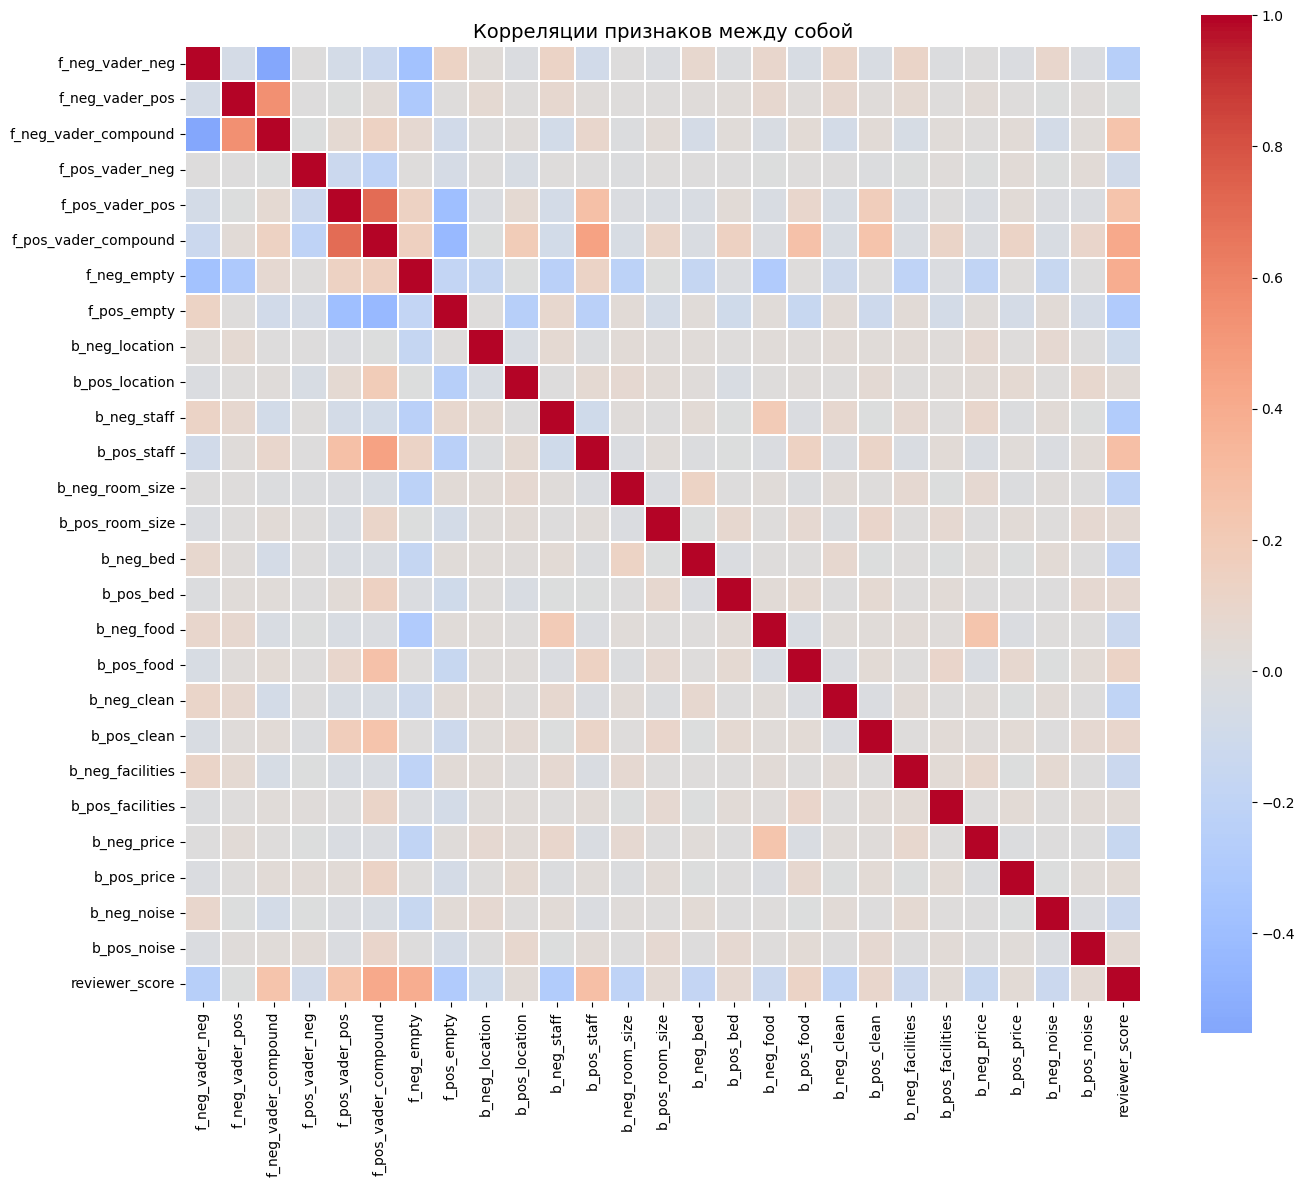

In [56]:
simple_corr_cols = (
    [c for c in hotels_final.columns if 'vader' in c] +
    ['f_neg_empty', 'f_pos_empty'] +
    [c for c in hotels_final.columns if c.startswith(('b_neg_', 'b_pos_')) and 'svd' not in c] +
    ['f_pos_topics_count', 'f_neg_topics_count', 'f_topic_balance'] +
    ['reviewer_score']
)
simple_corr_cols = [c for c in simple_corr_cols if c in hotels_final.columns]

np.random.seed(RANDOM_STATE)
sample = hotels_final[simple_corr_cols].sample(min(50000, len(hotels_final)), random_state=RANDOM_STATE)
corr = sample.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False,
            square=True, linewidths=0.3)
plt.title('Корреляции признаков между собой', fontsize=14)
plt.tight_layout()
plt.savefig('data/corr_heatmap.png', dpi=150)
plt.show()


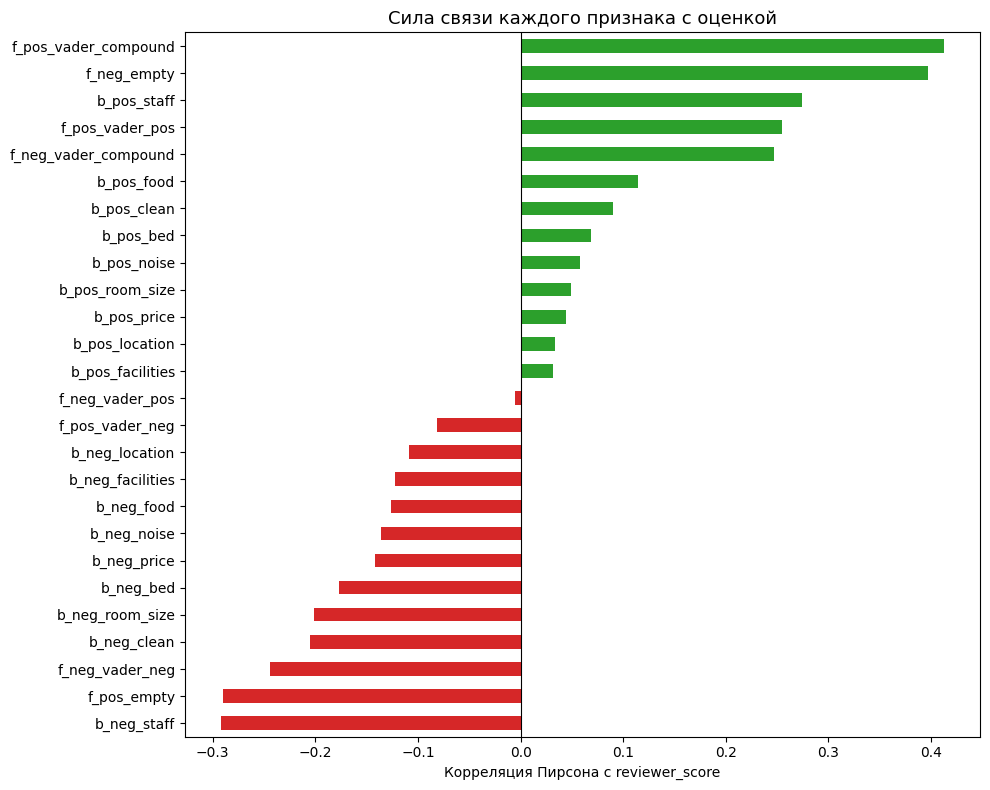

In [57]:
# корреляция каждого признака с таргетом
target_corr = hotels_final[simple_corr_cols].corr()['reviewer_score'].drop('reviewer_score')
target_corr = target_corr.sort_values()

plt.figure(figsize=(10, 8))
colors = ['#d62728' if v < 0 else '#2ca02c' for v in target_corr]
target_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Корреляция Пирсона с reviewer_score')
plt.title('Сила связи каждого признака с оценкой', fontsize=13)
plt.tight_layout()
plt.savefig('data/corr_with_target.png', dpi=150)
plt.show()

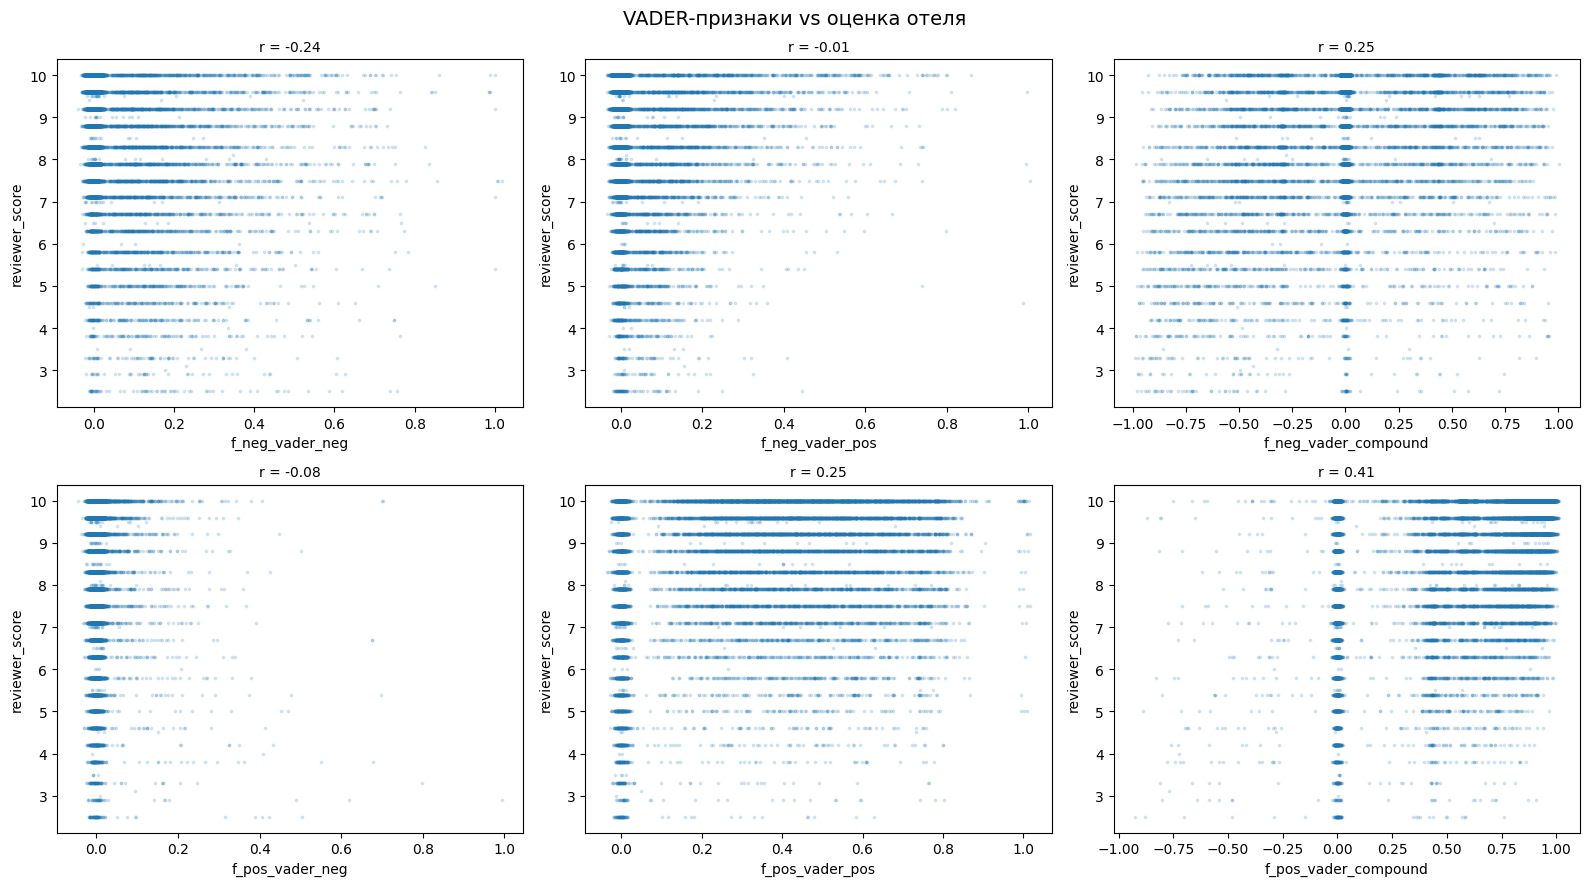

In [58]:
# Диаграммы рассеяния для самых сильных 
vader_cols = [c for c in review_df.columns if 'vader' in c]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, vader_cols):
    # jitter, чтобы точки не слипались в полосы
    x = review_df[col].sample(20000, random_state=RANDOM_STATE) + np.random.normal(0, 0.01, 20000)
    y = review_df['reviewer_score'].sample(20000, random_state=RANDOM_STATE)
    ax.scatter(x, y, s=3, alpha=0.15, color='#1f77b4')
    ax.set_xlabel(col)
    ax.set_ylabel('reviewer_score')
    r = review_df[[col, 'reviewer_score']].corr().iloc[0, 1]
    ax.set_title(f'r = {r:.2f}', fontsize=10)
plt.suptitle('VADER-признаки vs оценка отеля', fontsize=14)
plt.tight_layout()
plt.savefig('data/scatter_vader.png', dpi=150)
plt.show()

In [61]:
#  Ищем бесполезные пизнаки
feature_cols = [c for c in hotels_final.columns
                if c not in ('test_dataframe', 'reviewer_score')]

X = hotels_final[feature_cols]
y = hotels_final['reviewer_score']

report = pd.DataFrame({
    'corr_with_target': X.corrwith(y),
    'std': X.std(),
    'variance': X.var(),
    'unique_values': X.nunique(),
})

# слабая связь с таргетом и мало вариативности
useless = report[
    (report['corr_with_target'].abs() < 0.02) &
    ((report['std'] < 0.01) | (report['unique_values'] < 2))
].sort_values('corr_with_target')

print("=== Кандидаты на выброс ===")
print(useless)
print(f"\nВсего кандидатов: {len(useless)} из {len(feature_cols)}")


=== Кандидаты на выброс ===
            corr_with_target       std  variance  unique_values
b_bed_bunk          0.002497  0.004177  0.000017              2

Всего кандидатов: 1 из 305


In [62]:
# Сильно похожие признаки и их связь с таргетом

corr_matrix = X.corr().abs()

# Верхний треугольник, чтобы не считать пары дважды
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

THRESH = 0.8 

pairs = []
for col in upper.columns:
    for idx in upper.index[upper[col] > THRESH]:
        pairs.append({
            'feature_1': idx,
            'feature_2': col,
            'pair_corr': upper.loc[idx, col],
            'f1_vs_target': abs(hotels_final[idx].corr(y)),
            'f2_vs_target': abs(hotels_final[col].corr(y)),
        })

if not pairs:
    print(f"Пар с корреляцией > {THRESH} не нашлось. "
          "Проверим ближайшие к порогу пары:")
    stack = corr_matrix.stack().reset_index()
    stack.columns = ['feature_1', 'feature_2', 'pair_corr']
    stack = stack[stack['feature_1'] != stack['feature_2']]
    keep = stack['feature_1'] < stack['feature_2']
    stack = stack[keep].sort_values('pair_corr', ascending=False)
    print(stack.head(15).to_string(index=False))
else:
    similar = pd.DataFrame(pairs).sort_values('pair_corr', ascending=False).reset_index(drop=True)
    similar['drop_candidate'] = np.where(
        similar['f1_vs_target'] >= similar['f2_vs_target'],
        similar['feature_2'],
        similar['feature_1']
    )
    print(similar.to_string(index=False))



                   feature_1               feature_2  pair_corr  f1_vs_target  f2_vs_target               drop_candidate
              n_review_month      n_review_dayofyear   0.996227      0.032397      0.031985           n_review_dayofyear
             b_travel_family           b_type_family   0.986202      0.014152      0.014657              b_travel_family
              n_review_month        n_review_quarter   0.969874      0.032397      0.034595               n_review_month
                 f_pos_empty             f_pos_svd_0   0.968454      0.289597      0.252476                  f_pos_svd_0
            n_review_quarter      n_review_dayofyear   0.965855      0.034595      0.031985           n_review_dayofyear
               n_review_week      n_review_dayofyear   0.962360      0.032614      0.031985           n_review_dayofyear
              n_review_month           n_review_week   0.961279      0.032397      0.032614               n_review_month
            n_review_quarter    

In [63]:
# стабильность корреляции по подвыборкам
def stability_test(X, y, n_splits=5):
    rows = []
    for i in range(n_splits):
        part = X.sample(len(X) // 2, random_state=i)   # каждый раз новая половина
        idx = part.index
        rows.append(X.loc[idx].corrwith(y.loc[idx]).rename(f'split_{i}'))
    df = pd.concat(rows, axis=1)
    return pd.DataFrame({
        'mean_corr': df.mean(axis=1),
        'std_corr': df.std(axis=1),
        'stable': df.std(axis=1) < 0.02,   # флаг стабильности
    }).sort_values('mean_corr', key=abs, ascending=False)

print(stability_test(X, y))

                                   mean_corr  std_corr  stable
f_pos_vader_compound                0.412837  0.001652    True
f_neg_empty                         0.396525  0.000856    True
review_total_negative_word_counts  -0.383343  0.002333    True
average_score                       0.365206  0.001895    True
f_neg_svd_1                        -0.339704  0.001987    True
...                                      ...       ...     ...
f_neg_svd_65                       -0.000766  0.003164    True
b_type_loft                         0.000724  0.001760    True
f_neg_svd_27                       -0.000651  0.001797    True
b_amenity_wifi                     -0.000626  0.001087    True
b_accessible                       -0.000418  0.001741    True

[305 rows x 3 columns]


# Тренируем модель

In [69]:
# Тут нужно удалить признаки в тестах проявившие бесполезность
# Но их мало. Удалять не буду, если что-то не понравится -  удалю.
hotels_useless_removed_df: pd.DataFrame = hotels_final.copy()


In [70]:
# Приводим все к флоат, ибо модель все равно внутри конвертирует все наши инты в него
hotels_useless_removed_df = hotels_useless_removed_df.astype(np.float32)

In [71]:
# Разбиваем обратно  на обучающую и соревновательную  часть
train_df = (hotels_useless_removed_df[hotels_useless_removed_df['test_dataframe'] == 0]
    .drop(['test_dataframe'], axis=1))
test_df = (hotels_useless_removed_df[hotels_useless_removed_df['test_dataframe'] == 1]
    .drop(['test_dataframe'], axis=1))

In [72]:
# Разбираем обучающую и соревновательную часть на данные и скор, по которому и будем работать
X_train, y_train = train_df.drop(columns=['reviewer_score']), train_df['reviewer_score']
X_test,  y_test  = test_df.drop(columns=['reviewer_score']),  test_df['reviewer_score']

In [73]:
display(X_train.head(5))
X_train.info()

,additional_number_of_scoring,average_score,review_total_negative_word_counts,total_number_of_reviews,review_total_positive_word_counts,total_number_of_reviews_reviewer_has_given,days_since_review,lat,lng,n_country,...,f_pos_svd_90,f_pos_svd_91,f_pos_svd_92,f_pos_svd_93,f_pos_svd_94,f_pos_svd_95,f_pos_svd_96,f_pos_svd_97,f_pos_svd_98,f_pos_svd_99
0,581.0,8.4,3.0,1994.0,4.0,7.0,531.0,51.507893,-0.143671,5.0,...,0.010077,0.019644,-0.011508,-0.009847,1.989720e-02,0.006870,0.015637,-0.002375,0.002555,-0.003465
1,299.0,8.3,3.0,1361.0,2.0,14.0,203.0,51.521008,-0.123097,5.0,...,-0.006280,0.001952,-0.001313,0.000979,1.338811e-03,-0.009170,0.005377,-0.005849,-0.004799,-0.003515
2,32.0,8.9,6.0,406.0,0.0,14.0,289.0,48.845379,2.325643,1.0,...,0.000003,-0.000006,0.000010,-0.000007,-1.703398e-07,-0.000004,-0.000010,0.000004,0.000004,0.000004
3,34.0,7.5,0.0,607.0,11.0,8.0,681.0,48.888699,2.394540,1.0,...,-0.000813,0.011340,-0.016463,-0.051759,3.574949e-03,-0.048049,0.011087,-0.015195,-0.017904,0.017404
4,914.0,8.5,4.0,7586.0,20.0,10.0,516.0,52.385601,4.847060,3.0,...,-0.011796,0.021174,-0.025598,-0.015856,4.266652e-02,-0.038777,0.017154,0.063679,0.008783,0.092638


<class 'pandas.core.frame.DataFrame'>
Index: 386803 entries, 0 to 386802
Columns: 305 entries, additional_number_of_scoring to f_pos_svd_99
dtypes: float32(305)
memory usage: 453.0 MB


Так как в задании нет ограничений на используемые инструменты, буду делать на LGBMRegressor, он у меня на компьютере лучше шевелится

In [ ]:
# Создаём модель
model = LGBMRegressor(
    n_estimators=4000,
    learning_rate=0.05,
    num_leaves=63,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

# отрезаем 15% значений в тестовую выборку из train-части для валидационной выборки
X_train, X_eval_val, y_train, y_eval_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=RANDOM_STATE
)

# Обучаем модель
model.fit(
    X_train, y_train,                                   # Данные
    eval_X=X_eval_val, eval_y=y_eval_val,               # Валидационная выборка
    callbacks=[
        lightgbm.early_stopping(stopping_rounds=50),    # Если в течение 50 итераций подряд метрика не изменилась, то прекращаем. Лучше уже не будет
        lightgbm.log_evaluation(100),                   # печатать прогресс каждые 100 итераций
    ],
)

model.best_iteration_   # номер итерации с лучшей метрикой


y_pred_val = model.predict(X_eval_val, num_iteration=model.best_iteration_)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.057889 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 55339
[LightGBM] [Info] Number of data points in the train set: 201912, number of used features: 304
[LightGBM] [Info] Start training from score 8.395757
Training until validation scores don't improve for 50 rounds
[100]	valid_0's l2: 1.13852
[200]	valid_0's l2: 1.09413
[300]	valid_0's l2: 1.07905
[400]	valid_0's l2: 1.07313
[500]	valid_0's l2: 1.0693
[600]	valid_0's l2: 1.06704
[700]	valid_0's l2: 1.06576
[800]	valid_0's l2: 1.06425
[900]	valid_0's l2: 1.06292
Early stopping, best iteration is:
[902]	valid_0's l2: 1.06283


In [87]:
mae  = metrics.mean_absolute_error(y_eval_val, y_pred_val)
mape = metrics.mean_absolute_percentage_error(y_eval_val, y_pred_val)
r2   = metrics.r2_score(y_eval_val, y_pred_val)

print(f"MAE:  {mae:.3f} балла")
print(f"MAPE: {mape * 100:.1f}%")
print(f"R²:   {r2:.3f}")

MAE:  0.763 балла
MAPE: 10.9%
R²:   0.604


In [92]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
display("Топ-10 полезных:")
display(importance.head(10))
display("Нулевой вклад (кандидаты на выброс):")
display(importance[importance < 0.005].keys())

'Топ-10 полезных:'

f_pos_vader_compound                 1090
average_score                         911
review_total_negative_word_counts     764
f_neg_vader_compound                  675
review_total_positive_word_counts     559
f_pos_svd_1                           540
f_neg_svd_18                          521
f_pos_svd_0                           519
n_reviewer_nationality                475
f_neg_svd_1                           471
dtype: int32

'Нулевой вклад (кандидаты на выброс):'

Index(['b_pos_noise', 'b_review_is_weekend', 'n_review_quarter',
       'b_connecting', 'b_type_apartment', 'b_type_penthouse',
       'b_amenity_wifi', 'b_amenity_kitchen', 'b_amenity_parking',
       'b_amenity_breakfast', 'b_amenity_pool', 'b_unusual_floor',
       'b_shared_bath', 'b_view_canal', 'b_view_city', 'b_bed_bunk',
       'b_view_park', 'b_view_river', 'b_view_landmark', 'b_view_garden'],
      dtype='object')

In [95]:
X_sub = X_eval_val.sample(20000, random_state=RANDOM_STATE)
y_sub = y_eval_val.loc[X_sub.index]

result = permutation_importance(
    model, X_sub, y_sub,
    n_repeats=3,
    scoring='neg_mean_absolute_error',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

perm = pd.Series(result.importances_mean, index=X_sub.columns).sort_values(ascending=False)

print("Permutation-важность (топ-10):")
print(perm.head(10))
print("\nНенужные признаки (вклад отрицательный):")
print(perm[perm < 0])

Permutation-важность (топ-10):
f_pos_vader_compound                 0.091622
f_neg_svd_1                          0.074442
average_score                        0.060591
review_total_negative_word_counts    0.045840
f_pos_empty                          0.035762
f_pos_svd_0                          0.017018
review_total_positive_word_counts    0.016051
f_neg_empty                          0.014129
f_neg_vader_compound                 0.011575
f_neg_svd_7                          0.009915
dtype: float64

Ненужные признаки (вклад отрицательный):
f_pos_svd_63         -8.036587e-07
b_pos_food           -1.160600e-06
b_room_club          -1.291550e-06
b_type_family        -4.901278e-06
b_amenity_spa        -5.476585e-06
b_no_window          -7.386521e-06
b_room_standard      -7.949308e-06
b_room_deluxe        -8.205408e-06
b_travel_friends     -1.209864e-05
b_bed_single         -1.224373e-05
f_pos_svd_32         -1.395853e-05
b_bed_double         -1.399400e-05
f_neg_svd_57         -1.567002e-

In [99]:
X_corr = train_df.drop(columns=['reviewer_score'])
y_corr = train_df['reviewer_score']
corr_target = X_corr.corrwith(y_corr)

final = pd.DataFrame({
    'corr_target': corr_target,
    'rf_importance': importance.reindex(feature_cols),
    'perm_importance': perm.reindex(feature_cols),
    'dropped_as_duplicate': [c in set(similar['drop_candidate']) for c in feature_cols],
})

final['verdict'] = np.where(
    final['dropped_as_duplicate'], 'DROP (дубликат)',
    np.where(final['perm_importance'].isna(), 'нет данных',
             np.where(final['perm_importance'] <= 0, 'DROP (шум)',
                      np.where(final['corr_target'].abs() < 0.02, 'под вопросом', 'KEEP')))
)

order = ['DROP (дубликат)', 'DROP (шум)', 'под вопросом', 'нет данных', 'KEEP']
final['verdict'] = pd.Categorical(final['verdict'], categories=order, ordered=True)

final = final.sort_values(['verdict', 'perm_importance'],
                          ascending=[True, False])
display(final)
display('Итоги по вердиктам:')
display(final['verdict'].value_counts().reindex(order))


,corr_target,rf_importance,perm_importance,dropped_as_duplicate,verdict
f_pos_svd_0,-0.252476,519,0.017018,True,DROP (дубликат)
f_neg_svd_0,0.331197,339,0.001173,True,DROP (дубликат)
b_trip_business,-0.113428,44,0.000615,True,DROP (дубликат)
n_review_week,-0.032614,156,0.000264,True,DROP (дубликат)
additional_number_of_scoring,-0.061773,324,0.000152,True,DROP (дубликат)
...,...,...,...,...,...
n_review_season,0.032866,27,0.000010,False,KEEP
b_pos_facilities,0.032038,4,0.000010,False,KEEP
n_review_month_name,-0.030119,139,0.000010,False,KEEP
n_children,0.089770,1,0.000005,False,KEEP


'Итоги по вердиктам:'

verdict
DROP (дубликат)     11
DROP (шум)          54
под вопросом       110
нет данных           0
KEEP               130
Name: count, dtype: int64

# Предсказание и сохранение данных

In [106]:

y_pred = model.predict(X_test, num_iteration=model.best_iteration_)

raw_submission = pd.read_csv('data/competition/submission.zip')
submission = raw_submission.copy()
target_col = submission.columns[0]
assert len(submission) == len(y_pred)
submission[target_col] = y_pred
submission.to_csv('data/submission_final.csv', index=False)

print(submission.head())
print(submission[target_col].describe()) 


   reviewer_score      id
0        8.584908  488440
1        7.709194  274649
2        9.003163  374688
3        9.771614  404352
4        9.718462  451596
count    128935.000000
mean          8.395051
std           1.265606
min           1.227470
25%           7.729043
50%           8.740420
75%           9.366884
max          10.566758
Name: reviewer_score, dtype: float64
